In [7]:
# !pip install -q transformers

# Settings: one CSV, training-only PCA, InfoNCE, K-Means chemistry families


In [8]:
"""Shared settings for the glaze pipeline."""

CSV_PATH = "training_data.csv"

MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
MAX_LEN = 64
PCA_DIM = 16
SHARED_DIM = 256

SEED = 1
EPOCHS = 1000
LR = 1e-3
BATCH = 128
TEMPERATURE = 0.07

TEST_SIZE = 0.2
MAX_DIST = 0.01
LEAK_COS = 0.99

KS = (1, 5, 10)

# K-Means on training-only standardized PCA features.
# K is selected by silhouette on training recipes (no held-out tuning).
KMEANS_K_CANDIDATES = (5, 8, 10, 12, 15, 20)
KMEANS_SILHOUETTE_SAMPLE = 1500

# Explicit chemistry columns: image_path and descriptive metadata are NEVER model chemistry inputs.
OXIDE_COLS = "SiO2 Al2O3 CaO K2O Na2O Fe2O3 MgO TiO2 B2O3 P2O5 ZnO CuO CoO SrO Li2O ZrO2 SnO2 BaO Cr2O3 MnO MnO2 FeO NiO PbO F V2O5".split()


In [9]:
"""Data loading, cleaning, composition groups, leakage-filtered splits."""
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import GroupShuffleSplit


META_COLS = ["recipe_id", "image_path", "color_name", "hex_color", "Cone", "Surface", "Transparency", "Atmospheres"]


def load_glazes(path=CSV_PATH, encoding="latin-1"):
    """Read the single CSV once. Return (full cleaned DataFrame, normalized oxide fractions)."""
    raw = pd.read_csv(path, encoding=encoding)
    missing = [c for c in OXIDE_COLS if c not in raw.columns]
    if missing:
        raise ValueError(f"Missing oxide columns: {missing}")
    if raw["recipe_id"].isna().any() or not raw["recipe_id"].is_unique:
        raise ValueError("recipe_id must be non-null and unique")
    X = raw[OXIDE_COLS].fillna(0.0).to_numpy(dtype=np.float64)
    if not np.isfinite(X).all() or (X < 0).any():
        raise ValueError("Oxide columns contain negative or non-finite values")

    total = X.sum(axis=1)
    keep = total > 0
    df = raw.loc[keep].reset_index(drop=True)
    X = X[keep] / total[keep, None]
    return df, X


def model_input(X):
    """sqrt compresses the range so small colourant fractions carry more signal."""
    return np.sqrt(X).astype(np.float32)


def join_on_recipe_id(left, right, label="join"):
    """Inner join on recipe_id. Prints the counts so dropped recipes are visible."""
    assert left["recipe_id"].is_unique, f"{label}: duplicate recipe_id on the left"
    assert right["recipe_id"].is_unique, f"{label}: duplicate recipe_id on the right"
    out = left.merge(right, on="recipe_id", how="inner").reset_index(drop=True)
    print(f"{label}: left {len(left)}  right {len(right)}  joined {len(out)}")
    return out


def composition_groups(Xin, max_dist=MAX_DIST):
    """Complete-linkage clustering on cosine distance, so group size stays bounded."""
    model = AgglomerativeClustering(n_clusters=None, metric="cosine",
                                    linkage="complete", distance_threshold=max_dist)
    return model.fit_predict(Xin)


def split_by_composition(Xin, test_size, seed, max_dist=MAX_DIST, leak_cos=LEAK_COS):
    """Group-held-out split. Drops train recipes within leak_cos of any test recipe.
    Returns (train_idx, test_idx, groups, n_dropped)."""
    groups = composition_groups(Xin, max_dist=max_dist)
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
                  .split(np.zeros(len(groups)), groups=groups))
    sim = cosine_similarity(Xin[tr], Xin[te]).max(axis=1)
    keep = sim <= leak_cos
    return tr[keep], te, groups, int((~keep).sum())

# Applying training-only PCA to the chemistry stream + projection
The chemistry table is loaded once by `load_glazes()` in the training pipeline; this cell defines only the projection head.


In [10]:
"""Chemistry encoder: PCA-16 features, then a trainable projection."""
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
from sklearn.decomposition import PCA


PC_COLS = [f"pc{i}" for i in range(PCA_DIM)]


class ChemProjection(nn.Module):
    """Linear map from PCA features into the shared space, L2-normalised."""
    def __init__(self, in_dim=PCA_DIM, out_dim=SHARED_DIM):
        super().__init__()
        self.proj = nn.Linear(in_dim, out_dim)

    def forward(self, z):
        return F.normalize(self.proj(z), dim=1)

# Running Text stream through a Transformer + projection

In [11]:
"""Text encoder: descriptions, frozen MiniLM embeddings, trainable projection."""

import torch
from transformers import AutoTokenizer, AutoModel

def describe(row):
    """Text description. Blank fields become 'unknown' instead of 'nan'."""
    def get(col):
        v = row.get(col)
        return "unknown" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v)
    # return (f"color: {get('color_name')} ({get('hex_color')}), "
    return (f"color: {get('color_name')}, "
            f"Cone {get('Cone')}, {get('Surface')}, "
            f"{get('Transparency')}, {get('Atmospheres')}")


def mean_pooling(model_output, attention_mask):
    tokens = model_output[0]
    mask = attention_mask.unsqueeze(-1).expand(tokens.size()).float()
    return (tokens * mask).sum(1) / mask.sum(1).clamp(min=1e-9)


@torch.no_grad()
def embed_texts(texts, device):
    """Frozen MiniLM embeddings, mean pooled. Returns a (N, 384) tensor on CPU."""
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    enc = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
    out = []
    for i in range(0, len(texts), 256):
        batch = tok(texts[i:i + 256], padding=True, truncation=True,
                    max_length=MAX_LEN, return_tensors="pt").to(device)
        out.append(mean_pooling(enc(**batch), batch["attention_mask"]).cpu())
    return torch.cat(out)


class TextProjection(nn.Module):
    """Linear map from 384-d MiniLM embeddings into the shared space, L2-normalised."""
    def __init__(self, in_dim=384, out_dim=SHARED_DIM):
        super().__init__()
        self.proj = nn.Linear(in_dim, out_dim)

    def forward(self, x):
        return F.normalize(self.proj(x), dim=1)

# Shared space training + Evaluation

In [12]:
"""Train the shared text-chemistry space with masked InfoNCE, evaluate label-free."""

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Import the shared configurations and functions from our glaze_data module
 # Data helpers are defined above in this notebook (no generated Python modules).

from pathlib import Path

OUTPUT_DIR = Path.cwd()
SAVE_PATH = OUTPUT_DIR / "shared_space_heads.pt"


def info_nce_masked(a, b, group_ids, temperature=TEMPERATURE):
    """Symmetric InfoNCE that ignores other rows from the same group."""
    logits = a @ b.T / temperature
    n = a.size(0)
    same = (group_ids[:, None] == group_ids[None, :]) & ~torch.eye(
        n, dtype=torch.bool, device=a.device)
    logits = logits.masked_fill(same, float("-inf"))
    labels = torch.arange(n, device=a.device)
    return (F.cross_entropy(logits, labels) + F.cross_entropy(logits.T, labels)) / 2


def build_paired_data(device):
    """Read once; keep recipe order aligned across chemistry, text and metadata."""
    df, X_mass = load_glazes()
    texts = df.apply(describe, axis=1).tolist()
    assert len(df) == len(X_mass) == len(texts)
    return {
        "recipe_ids": df["recipe_id"].to_numpy(),
        "texts": texts,
        "metadata": df.copy(),  # retain all original columns, including image_path
        "Xin": model_input(X_mass),
        "Xmass": X_mass.astype(np.float32),
        "text_emb": embed_texts(texts, device).cpu(),
        # PCA features are fitted after splitting in main().
    }


def train_heads(text_emb, chem_feat, group_id, tr, device, verbose=False):
    text_head = TextProjection(out_dim=SHARED_DIM).to(device)
    chem_head = ChemProjection(out_dim=SHARED_DIM).to(device)
    opt = torch.optim.Adam(list(text_head.parameters()) + list(chem_head.parameters()), lr=LR)
    dl = DataLoader(TensorDataset(text_emb[tr], chem_feat[tr], group_id[tr]),
                    batch_size=BATCH, shuffle=True)

    for epoch in range(1, EPOCHS + 1):
        text_head.train()
        chem_head.train()
        total, n = 0.0, 0
        for t, c, g in dl:
            t, c, g = t.to(device), c.to(device), g.to(device)
            loss = info_nce_masked(text_head(t), chem_head(c), g)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(t)
            n += len(t)
        if verbose:
            print(f"epoch {epoch:3d}  train loss={total / n:.4f}")

    text_head.eval()
    chem_head.eval()
    return text_head, chem_head


def embed_heldout(text_head, chem_head, text_emb, chem_feat, te, device):
    with torch.no_grad():
        Qt = text_head(text_emb[te].to(device)).cpu().numpy()
        Qc = chem_head(chem_feat[te].to(device)).cpu().numpy()
    return Qt, Qc


def alignment_report(Qt, Qc, g, ks=KS):
    """Recall of each text's true chemistry partner. Same-group candidates excluded,
    except the true partner. Random baseline for R@k is k / (m + 1)."""
    sims = Qt @ Qc.T
    n = len(Qt)
    diag = np.diag(sims).copy()
    off_mean = (sims.sum() - diag.sum()) / (n * (n - 1))
    order = np.argsort(-sims, axis=1)

    hits = {k: [] for k in ks}
    rand = {k: [] for k in ks}
    for i in range(n):
        cand = order[i]
        cand = cand[(g[cand] != g[i]) | (cand == i)]
        rank = int(np.where(cand == i)[0][0])
        m = int((g != g[i]).sum())
        for k in ks:
            hits[k].append(rank < k)
            rand[k].append(min(1.0, k / (m + 1)))

    out = {"true_cos": float(diag.mean()), "off_diag_cos": float(off_mean)}
    for k in ks:
        out[f"R@{k}"] = float(np.mean(hits[k]))
        out[f"random_R@{k}"] = float(np.mean(rand[k]))
    return out


def agreement_report(Q, D, Xq, Xd, g, ks=KS):
    """Mean MAD between each query's composition and its top-k retrieved compositions."""
    sims = Q @ D.T
    order = np.argsort(-sims, axis=1)
    vals = {k: [] for k in ks}
    for i in range(len(Q)):
        cand = order[i]
        cand = cand[g[cand] != g[i]][:max(ks)]
        if len(cand) == 0:
            continue
        d = np.abs(Xd[cand] - Xq[i]).mean(axis=1)
        for k in ks:
            vals[k].append(d[:k].mean())
    return {f"MAD@{k}": float(np.mean(vals[k])) for k in ks}


def random_agreement(Xq, g):
    vals = []
    for i in range(len(Xq)):
        m = g != g[i]
        if m.any():
            vals.append(np.abs(Xq[m] - Xq[i]).mean(axis=1).mean())
    return float(np.mean(vals))


def near_duplicate_report(Xin_train, Xin_test, thresholds=(0.95, 0.99)):
    sim = cosine_similarity(Xin_test, Xin_train).max(axis=1)
    q50, q90, q99 = np.percentile(sim, [50, 90, 99])
    print("\nNear-duplicate check (max cosine to a train recipe)")
    print(f"  median={q50:.4f}  90th={q90:.4f}  99th={q99:.4f}")
    for t in thresholds:
        print(f"  held-out with a train neighbour at cos>{t}: {(sim > t).mean():.3f}")


def main():
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    data = build_paired_data(device)
    tr, te, groups, n_dropped = split_by_composition(
        data["Xin"], TEST_SIZE, SEED, MAX_DIST, LEAK_COS)
    print(f"groups: {len(np.unique(groups))}  largest group: {np.bincount(groups).max()}")
    print(f"train recipes: {len(tr)}  held-out recipes: {len(te)}  "
          f"dropped from train by leakage filter: {n_dropped}")

    # Fit PCA only on training compositions; use the SAME fitted transform everywhere.
    pca = PCA(n_components=PCA_DIM, random_state=SEED)
    pca.fit(data["Xin"][tr])
    data["chem_feat"] = torch.tensor(pca.transform(data["Xin"]).astype(np.float32))
    print(f"PCA explained variance ({PCA_DIM} components): {pca.explained_variance_ratio_.sum():.3f}")

    text_head, chem_head = train_heads(
        data["text_emb"], data["chem_feat"], torch.tensor(groups), tr, device, verbose=True)
    Qt, Qc = embed_heldout(text_head, chem_head, data["text_emb"], data["chem_feat"], te, device)

    g = groups[te]
    Xm = data["Xmass"][te]

    print("\nAlignment (held-out, same-group excluded except true partner)")
    al = alignment_report(Qt, Qc, g)
    print(f"  true-pair cosine={al['true_cos']:.4f}  off-diagonal cosine={al['off_diag_cos']:.4f}")
    for k in KS:
        print(f"  R@{k}: trained={al[f'R@{k}']:.3f}  random={al[f'random_R@{k}']:.3f}")

    print("\nChemical agreement (MAD over 26 mass fractions, lower is better)")
    print(f"  random retrieval baseline MAD = {random_agreement(Xm, g):.4f}")
    for name, (Q, D) in {"text->chem": (Qt, Qc), "chem->text": (Qc, Qt)}.items():
        ag = agreement_report(Q, D, Xm, Xm, g)
        print(f"  {name}: " + "  ".join(f"MAD@{k}={ag[f'MAD@{k}']:.4f}" for k in KS))

    torch.save({"text_head": text_head.state_dict(),
                "chem_head": chem_head.state_dict(),
                "shared_dim": SHARED_DIM,
                "pca_mean": pca.mean_, "pca_components": pca.components_,
                "pca_explained_variance_ratio": pca.explained_variance_ratio_,
                "model_name": MODEL_NAME, "max_len": MAX_LEN,
                "pca_dim": PCA_DIM, "temperature": TEMPERATURE},
               SAVE_PATH)
    print(f"\nsaved {SAVE_PATH}")

    near_duplicate_report(data["Xin"][tr], data["Xin"][te])

    # K-Means is a parallel chemical-family analysis of the PCA features.
    # PCA and the StandardScaler are fitted ONLY on training recipes.
    from sklearn.cluster import KMeans
    from sklearn.preprocessing import StandardScaler
    from sklearn.metrics import silhouette_score
    import joblib

    pca_all = data["chem_feat"].numpy()
    cluster_scaler = StandardScaler().fit(pca_all[tr])
    cluster_train = cluster_scaler.transform(pca_all[tr])
    cluster_all = cluster_scaler.transform(pca_all)
    candidate_ks = [k for k in KMEANS_K_CANDIDATES if 2 <= k < len(tr)]
    if not candidate_ks:
        raise ValueError("Not enough training recipes for K-Means")
    rng = np.random.default_rng(SEED)
    sample_idx = rng.choice(len(tr), min(KMEANS_SILHOUETTE_SAMPLE, len(tr)), replace=False)
    diagnostics = []
    for k in candidate_ks:
        km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(cluster_train)
        sample_labels = km.predict(cluster_train[sample_idx])
        score = (silhouette_score(cluster_train[sample_idx], sample_labels)
                 if len(set(sample_labels)) >= 2 else float('nan'))
        diagnostics.append({"k": k, "silhouette": score,
                            "largest_cluster_fraction": float(np.bincount(km.labels_).max()/len(tr))})
    diagnostics_df = pd.DataFrame(diagnostics)
    best_row = diagnostics_df.sort_values(["silhouette", "k"], ascending=[False, True]).iloc[0]
    chosen_k = int(best_row["k"])
    kmeans = KMeans(n_clusters=chosen_k, random_state=SEED, n_init=10).fit(cluster_train)
    labels = kmeans.predict(cluster_all)
    print(f"K-Means selected k={chosen_k}; silhouette={best_row['silhouette']:.3f}")
    print("K-Means cluster sizes (training):", np.bincount(kmeans.labels_).tolist())

    # Build searchable index of recipes (including held-out, for demonstration).
    # For unbiased TEST metrics, do not search the held-out set during model selection.
    with torch.no_grad():
        chem_vectors = chem_head(data["chem_feat"].to(device)).cpu().numpy()
    index = data["metadata"].copy()
    index["text"] = data["texts"]
    index["kmeans_cluster"] = labels
    index["split"] = "excluded_train"
    index.loc[tr, "split"] = "train"
    index.loc[te, "split"] = "test"
    index.to_csv(OUTPUT_DIR / "glaze_retrieval_catalog.csv", index=False)
    np.savez_compressed(OUTPUT_DIR / "glaze_retrieval_vectors.npz",
                        recipe_ids=data["recipe_ids"].astype(str), vectors=chem_vectors)
    import joblib
    joblib.dump({"pca": pca, "cluster_scaler": cluster_scaler,
                 "kmeans": kmeans, "cluster_labels": labels, "chosen_k": chosen_k},
                OUTPUT_DIR / "glaze_chemistry_models.joblib")
    print("Saved catalog, vectors, and PCA/K-Means model artifacts.")



# Run shared-space training

In [13]:
# Since the training logic is already defined in the cell above (Kc8yGwXgaMqB),
# we can simply run the main function directly here instead of using %run:
# main()

## Local outputs

The notebook saves the projection heads, catalog, vectors, training-only PCA and K-Means artifacts in the current working directory.


In [14]:
from pathlib import Path
print("Model checkpoint:", Path("shared_space_heads.pt").resolve())
print("Catalog:", Path("glaze_retrieval_catalog.csv").resolve())
print("Vectors:", Path("glaze_retrieval_vectors.npz").resolve())


Model checkpoint: /Users/claire/Documents/AIS/GC2/training_new/test_similarity/shared_space_heads.pt
Catalog: /Users/claire/Documents/AIS/GC2/training_new/test_similarity/glaze_retrieval_catalog.csv
Vectors: /Users/claire/Documents/AIS/GC2/training_new/test_similarity/glaze_retrieval_vectors.npz


## Text-only retrieval with CIEDE2000 and image galleries

Score **every eligible recipe** using 40% latent similarity, 40% CIEDE2000 color similarity, 10% surface match, and 10% cone match. K-Means optionally diversifies the top results; it does not alter their scores. The original `image_path` is used only to display photos, never for training.


In [15]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from skimage.color import rgb2lab, deltaE_ciede2000
from transformers import AutoTokenizer, AutoModel

ROOT = Path.cwd()
catalog = pd.read_csv(ROOT / "glaze_retrieval_catalog.csv")
vectors = np.load(ROOT / "glaze_retrieval_vectors.npz", allow_pickle=False)
assert len(catalog) == len(vectors["vectors"])
assert np.array_equal(catalog.recipe_id.astype(str).to_numpy(), vectors["recipe_ids"].astype(str))
chem_vectors = vectors["vectors"]

def parse_hex(h):
    if not isinstance(h, str):
        return None
    h = h.strip().lstrip("#")
    if len(h) == 3 and re.fullmatch(r"[0-9a-fA-F]{3}", h):
        h = "".join(c * 2 for c in h)
    if not re.fullmatch(r"[0-9a-fA-F]{6}", h):
        return None
    return np.array([int(h[i:i+2], 16) for i in (0, 2, 4)]) / 255.0

rgb = [parse_hex(h) for h in catalog["hex_color"]]
valid_hex = np.array([v is not None for v in rgb])
lab = np.full((len(catalog), 3), np.nan)
if valid_hex.any():
    lab[valid_hex] = rgb2lab(np.stack([v for v in rgb if v is not None]).reshape(-1, 1, 3)).reshape(-1, 3)

def cone_overlap(query, actual):
    def parse(s):
        s = str(s).replace("½", ".5").replace("–", "-").replace("—", "-")
        s = re.sub(r"(\d+)\s+1/2", lambda m: str(float(m.group(1)) + 0.5), s)
        nums = [float(x) for x in re.findall(r"\d+(?:\.\d+)?", s)]
        return (min(nums), max(nums)) if nums else None
    a, b = parse(query), parse(actual)
    return np.nan if a is None or b is None else float(max(a[0], b[0]) <= min(a[1], b[1]))

checkpoint = torch.load(ROOT / "shared_space_heads.pt", map_location="cpu", weights_only=False)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained(checkpoint.get("model_name", MODEL_NAME))
encoder = AutoModel.from_pretrained(checkpoint.get("model_name", MODEL_NAME)).to(device).eval()
text_head = TextProjection(out_dim=checkpoint["shared_dim"]).to(device).eval()
text_head.load_state_dict(checkpoint["text_head"])

def retrieve_glazes(color, surface, cone, query_hex, top_k=10,
                    diversify=False, max_per_cluster=2, allowed_splits=None,
                    latent_weight=0.40, color_weight=0.40,
                    surface_weight=0.10, cone_weight=0.10):
    """Score ALL eligible recipes, then optionally diversify with K-Means.

    Default weights: 40% shared latent similarity, 40% CIEDE2000 color,
    10% surface and 10% cone. Missing metadata contributes zero, and is
    flagged by metadata_coverage. K-Means only affects selection, not score.
    """
    weights = np.array([latent_weight, color_weight, surface_weight, cone_weight], dtype=float)
    if not np.isfinite(weights).all() or (weights < 0).any() or not np.isclose(weights.sum(), 1.0):
        raise ValueError("Ranking weights must be nonnegative and sum to 1")
    if top_k < 1 or max_per_cluster < 1:
        raise ValueError("top_k and max_per_cluster must be >= 1")
    rgb_q = parse_hex(query_hex)
    if rgb_q is None:
        raise ValueError("query_hex must be a valid #RRGGBB or #RGB color")
    lab_q = rgb2lab(rgb_q.reshape(1, 1, 3)).reshape(3)
    query = f"color: {color}, Cone {cone}, {surface}, unknown, unknown"
    batch = tokenizer([query], padding=True, truncation=True,
                      max_length=checkpoint.get("max_len", MAX_LEN), return_tensors="pt").to(device)
    with torch.no_grad():
        q = text_head(mean_pooling(encoder(**batch), batch["attention_mask"])).cpu().numpy()[0]
    similarity = chem_vectors @ q
    eligible = (np.arange(len(catalog)) if allowed_splits is None else
                np.flatnonzero(catalog["split"].isin(allowed_splits).to_numpy()))
    if len(eligible) == 0:
        raise ValueError("No eligible recipes")
    # No latent top-200 bottleneck: every eligible recipe gets a color score.
    ranked = catalog.iloc[eligible].copy()
    ranked["latent_similarity"] = similarity[eligible]
    delta = np.full(len(eligible), np.nan)
    ok = valid_hex[eligible]
    if ok.any():
        delta[ok] = deltaE_ciede2000(
            np.broadcast_to(lab_q, (ok.sum(), 3)).reshape(-1, 1, 3),
            lab[eligible[ok]].reshape(-1, 1, 3)
        ).reshape(-1)
    ranked["delta_e_2000"] = delta
    ranked["color_score"] = np.exp(-delta / 20.0)
    actual_surface = ranked["Surface"].fillna("").astype(str).str.strip().str.casefold()
    ranked["surface_match"] = np.where(
        actual_surface.isin(["", "unknown", "nan", "none"]), np.nan,
        (actual_surface == str(surface).strip().casefold()).astype(float)
    )
    ranked["cone_match"] = ranked["Cone"].map(lambda v: cone_overlap(cone, v))
    fields = ["color_score", "surface_match", "cone_match"]
    ranked["metadata_coverage"] = ranked[fields].notna().mean(axis=1)
    ranked["latent_score"] = (ranked["latent_similarity"].clip(-1, 1) + 1) / 2
    ranked["final_score"] = (
        latent_weight * ranked["latent_score"] +
        color_weight * ranked["color_score"].fillna(0) +
        surface_weight * ranked["surface_match"].fillna(0) +
        cone_weight * ranked["cone_match"].fillna(0)
    )
    ranked = ranked.sort_values(["final_score", "latent_similarity"],
                                ascending=False, kind="stable")
    if diversify:
        selected, counts = [], {}
        for idx, row in ranked.iterrows():
            cluster = int(row["kmeans_cluster"])
            if counts.get(cluster, 0) < max_per_cluster:
                selected.append(idx)
                counts[cluster] = counts.get(cluster, 0) + 1
            if len(selected) == top_k:
                break
        if len(selected) < top_k:
            selected.extend(idx for idx in ranked.index if idx not in selected)
        ranked = ranked.loc[selected]
    return ranked.head(top_k).reset_index(drop=True)


# Display retrieved glaze photographs from the preserved image_path column.
# Relative paths are resolved against the notebook working directory.
from PIL import Image, ImageOps, ImageDraw
import matplotlib.pyplot as plt
from urllib.parse import urlparse
from urllib.request import urlopen
from io import BytesIO

def _open_recipe_image(image_path, base_dir=None):
    """Return a PIL image, or None if missing/unreadable."""
    if pd.isna(image_path) or not str(image_path).strip():
        return None
    path_str = str(image_path).strip()
    try:
        if urlparse(path_str).scheme in ("https", "http"):
            # Optional: web-hosted image URLs require local internet access.
            with urlopen(path_str, timeout=8) as response:
                content = response.read(12_000_000)
            return Image.open(BytesIO(content)).convert("RGB")
        path = Path(path_str).expanduser()
        if not path.is_absolute():
            path = (Path(base_dir) if base_dir is not None else Path.cwd()) / path
        return Image.open(path).convert("RGB")
    except Exception as exc:
        print(f"Image unavailable: {path_str} ({type(exc).__name__})")
        return None

def show_glaze_gallery(results, title="Retrieved glazes", columns=5, image_base_dir=None):
    """Show images in retrieval order with name, color, score and cluster."""
    if "image_path" not in results.columns:
        raise ValueError("The retrieval catalog has no image_path column")
    if results.empty:
        print("No recipes to display")
        return
    count = len(results)
    columns = min(columns, count)
    rows = int(np.ceil(count / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(3.0 * columns, 3.9 * rows), squeeze=False)
    fig.suptitle(title, fontsize=15, y=1.005)
    for rank, (_, recipe) in enumerate(results.iterrows(), 1):
        ax = axes[(rank - 1) // columns, (rank - 1) % columns]
        image = _open_recipe_image(recipe.get("image_path"), image_base_dir)
        if image is None:
            image = Image.new("RGB", (350, 280), "#e5e7eb")
            draw = ImageDraw.Draw(image)
            draw.text((80, 130), "Image unavailable", fill="#333333")
        ax.imshow(ImageOps.contain(image, (400, 320)))
        ax.set_axis_off()
        name = str(recipe.get("Name", recipe.get("recipe_id", "Glaze")))
        if len(name) > 31:
            name = name[:28] + "..."
        cluster = recipe.get("kmeans_cluster", "?")
        score = recipe.get("final_score", np.nan)
        ax.set_title(f"#{rank} {name}\nScore: {score:.3f} | K-Means: {cluster}", fontsize=9)
    for ax in axes.flat[count:]:
        ax.set_axis_off()
    fig.tight_layout()
    plt.show()
    plt.close(fig)


Best matching recipes


,recipe_id,color_name,hex_color,Surface,Cone,kmeans_cluster,latent_similarity,delta_e_2000,color_score,final_score,image_path
0,327321,cobalt blue,#2B5588,Glossy,5 - 6,2,0.456418,4.370202,0.803715,0.812770,https://cdn.glazy.org/public/uploads/recipes/2...
1,150980,cobalt blue,#2757BB,Glossy,4 - 7,8,0.319423,2.943150,0.863158,0.809148,https://cdn.glazy.org/public/uploads/recipes/8...
2,614040,cobalt blue,#375E9D,Glossy,6 - 7,8,0.268047,3.680404,0.831919,0.786377,https://cdn.glazy.org/public/uploads/recipes/4...
3,10967,cobalt blue,#465A90,Glossy,6,5,0.334518,4.801724,0.786560,0.781528,https://cdn.glazy.org/public/uploads/recipes/6...
4,462496,cobalt blue,#1F448C,Glossy,6 - 8,8,0.315285,5.840731,0.746741,0.761753,https://cdn.glazy.org/public/uploads/recipes/9...
5,10975,cobalt blue,#3C6292,Glossy,6,8,0.271885,5.481678,0.760268,0.758484,https://cdn.glazy.org/public/uploads/recipes/7...
6,22716,cobalt blue,#495EB2,Glossy,6,8,0.212751,4.734709,0.789200,0.758230,https://cdn.glazy.org/public/uploads/recipes/1...
7,700509,cobalt blue,#335470,Glossy,5 - 6,8,0.349167,7.240937,0.696250,0.748333,https://cdn.glazy.org/public/uploads/recipes/0...
8,2402,cobalt blue,#2C4976,Glossy,6,5,0.315577,6.926855,0.707270,0.746023,https://cdn.glazy.org/public/uploads/recipes/0...
9,7600,cobalt blue,#5362AD,Glossy,6,0,0.235500,6.501342,0.722479,0.736092,https://cdn.glazy.org/public/uploads/recipes/0...


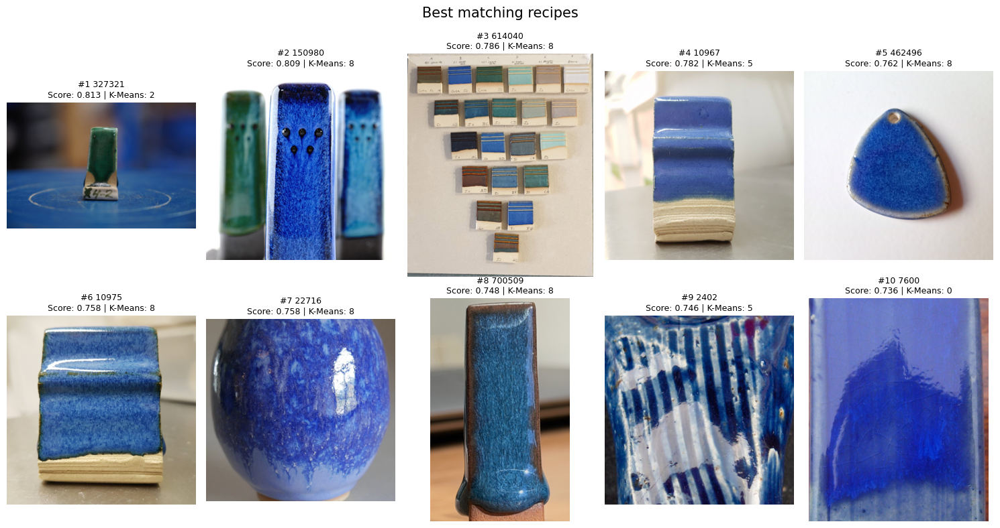

Explore different chemical formulations


,recipe_id,color_name,hex_color,Surface,Cone,kmeans_cluster,latent_similarity,delta_e_2000,color_score,final_score,image_path
0,327321,cobalt blue,#2B5588,Glossy,5 - 6,2,0.456418,4.370202,0.803715,0.812770,https://cdn.glazy.org/public/uploads/recipes/2...
1,150980,cobalt blue,#2757BB,Glossy,4 - 7,8,0.319423,2.943150,0.863158,0.809148,https://cdn.glazy.org/public/uploads/recipes/8...
2,614040,cobalt blue,#375E9D,Glossy,6 - 7,8,0.268047,3.680404,0.831919,0.786377,https://cdn.glazy.org/public/uploads/recipes/4...
3,10967,cobalt blue,#465A90,Glossy,6,5,0.334518,4.801724,0.786560,0.781528,https://cdn.glazy.org/public/uploads/recipes/6...
4,2402,cobalt blue,#2C4976,Glossy,6,5,0.315577,6.926855,0.707270,0.746023,https://cdn.glazy.org/public/uploads/recipes/0...
5,7600,cobalt blue,#5362AD,Glossy,6,0,0.235500,6.501342,0.722479,0.736092,https://cdn.glazy.org/public/uploads/recipes/0...
6,510633,cobalt blue,#1F50A7,Satin-matte,5 - 7,4,0.264339,1.825022,0.912788,0.717983,https://cdn.glazy.org/public/uploads/recipes/3...
7,646323,navy blue,#343775,Glossy,5 - 7,2,0.466741,11.750307,0.555706,0.715631,https://cdn.glazy.org/public/uploads/recipes/2...
8,749408,navy blue,#163A8A,Glossy,5 - 6,4,0.276107,8.602760,0.650419,0.715389,https://cdn.glazy.org/public/uploads/recipes/0...
9,3056,cobalt blue,#283B9E,Glossy,6,0,0.234709,8.214523,0.663169,0.712209,https://cdn.glazy.org/public/uploads/recipes/5...


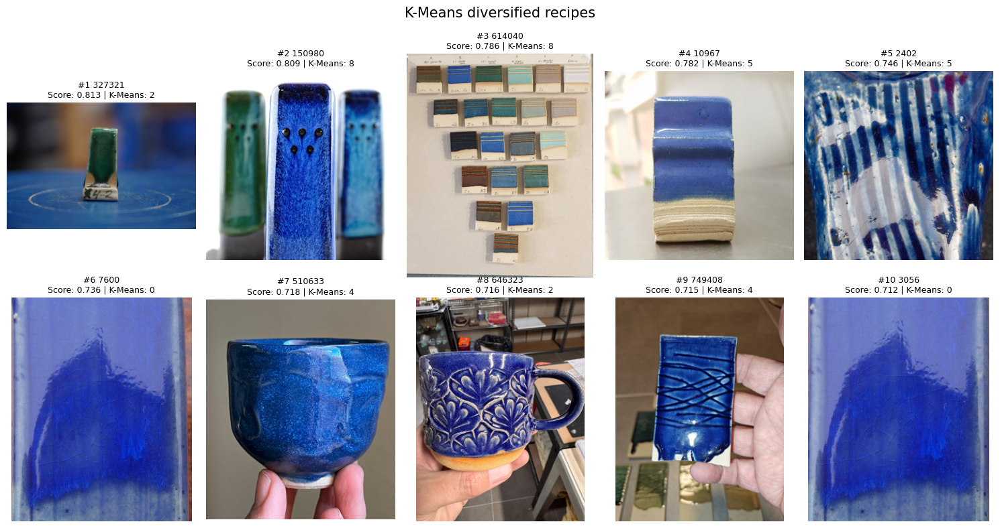

In [16]:
# Change these values to try another text + color query.
query_args = dict(color="Blue", surface="Glossy", cone="6", query_hex="#3054A5", top_k=10)
plain = retrieve_glazes(**query_args, diversify=False)
diverse = retrieve_glazes(**query_args, diversify=True, max_per_cluster=2)

show_cols = ["recipe_id", "Name", "color_name", "hex_color", "Surface", "Cone",
             "kmeans_cluster", "latent_similarity", "delta_e_2000",
             "color_score", "final_score", "image_path"]
print("Best matching recipes")
display(plain[[c for c in show_cols if c in plain.columns]])
show_glaze_gallery(plain, "Best matching recipes")

print("Explore different chemical formulations")
display(diverse[[c for c in show_cols if c in diverse.columns]])
show_glaze_gallery(diverse, "K-Means diversified recipes")


Best matching recipes


,recipe_id,color_name,hex_color,Surface,Cone,kmeans_cluster,latent_similarity,delta_e_2000,color_score,final_score,image_path
0,581971,straw yellow,#C7D081,Glossy,5.5 - 10,2,0.518543,17.683069,0.413064,0.668934,https://cdn.glazy.org/public/uploads/recipes/7...
1,145012,seafoam green,#76C9AF,Glossy,5 - 6,5,0.374522,18.369083,0.399136,0.634559,https://cdn.glazy.org/public/uploads/recipes/1...
2,242342,straw yellow,#D4CD8D,Glossy,5.5 - 6,2,0.509219,22.105558,0.331119,0.634291,https://cdn.glazy.org/public/uploads/recipes/4...
3,650627,mustard yellow,#C1BD42,Glossy,5 - 6,2,0.472976,22.849727,0.319025,0.622205,https://cdn.glazy.org/public/uploads/recipes/2...
4,692274,ash gray,#CAD0C1,Glossy,5.5 - 6,2,0.492226,24.015876,0.300955,0.618827,https://cdn.glazy.org/public/uploads/recipes/7...
5,698480,lemon yellow,#DCE776,Glossy,6,0,0.243032,18.008243,0.406402,0.611167,https://cdn.glazy.org/public/uploads/recipes/8...
6,673963,green gray,#999E93,Glossy,6,2,0.550832,28.554609,0.239853,0.606107,https://cdn.glazy.org/public/uploads/recipes/6...
7,371189,oatmeal,#E2D1B5,Glossy,6,2,0.532693,28.464295,0.240938,0.602914,https://cdn.glazy.org/public/uploads/recipes/8...
8,347999,warm gray,#B1AB95,Glossy,6,2,0.494079,27.355330,0.254675,0.600686,https://cdn.glazy.org/public/uploads/recipes/9...
9,117732,ash gray,#B2B09A,Glossy,6,0,0.453365,25.853240,0.274539,0.600489,https://cdn.glazy.org/public/uploads/recipes/3...


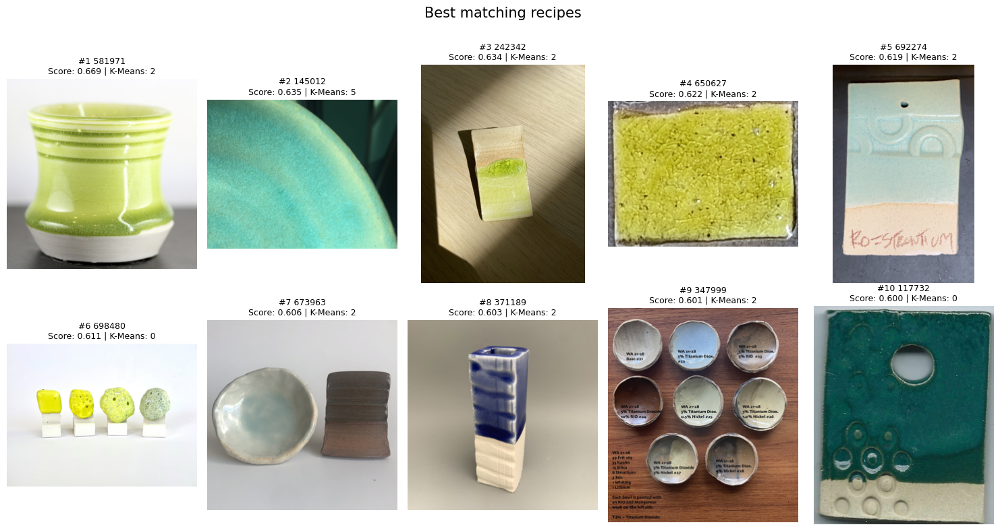

Explore different chemical formulations


,recipe_id,color_name,hex_color,Surface,Cone,kmeans_cluster,latent_similarity,delta_e_2000,color_score,final_score,image_path
0,581971,straw yellow,#C7D081,Glossy,5.5 - 10,2,0.518543,17.683069,0.413064,0.668934,https://cdn.glazy.org/public/uploads/recipes/7...
1,145012,seafoam green,#76C9AF,Glossy,5 - 6,5,0.374522,18.369083,0.399136,0.634559,https://cdn.glazy.org/public/uploads/recipes/1...
2,242342,straw yellow,#D4CD8D,Glossy,5.5 - 6,2,0.509219,22.105558,0.331119,0.634291,https://cdn.glazy.org/public/uploads/recipes/4...
3,698480,lemon yellow,#DCE776,Glossy,6,0,0.243032,18.008243,0.406402,0.611167,https://cdn.glazy.org/public/uploads/recipes/8...
4,117732,ash gray,#B2B09A,Glossy,6,0,0.453365,25.853240,0.274539,0.600489,https://cdn.glazy.org/public/uploads/recipes/3...
5,331318,light gray,#D9DFDD,Glossy,6 - 4,11,0.492044,27.328646,0.255015,0.600415,https://cdn.glazy.org/public/uploads/recipes/1...
6,6050,celadon green,#89BD93,Glossy,6,4,0.051497,16.112580,0.446807,0.589022,https://cdn.glazy.org/public/uploads/recipes/5...
7,516089,jade green,#64957B,Glossy,3 - 6,5,0.399374,26.324839,0.268141,0.587131,https://cdn.glazy.org/public/uploads/recipes/8...
8,636675,light gray,#D5D6D0,Glossy,4 - 6,8,0.393924,26.756073,0.262421,0.583753,https://cdn.glazy.org/public/uploads/recipes/7...
9,692270,sage green,#B1B78F,Glossy,5.5 - 6,4,0.210230,21.499248,0.341311,0.578570,https://cdn.glazy.org/public/uploads/recipes/7...


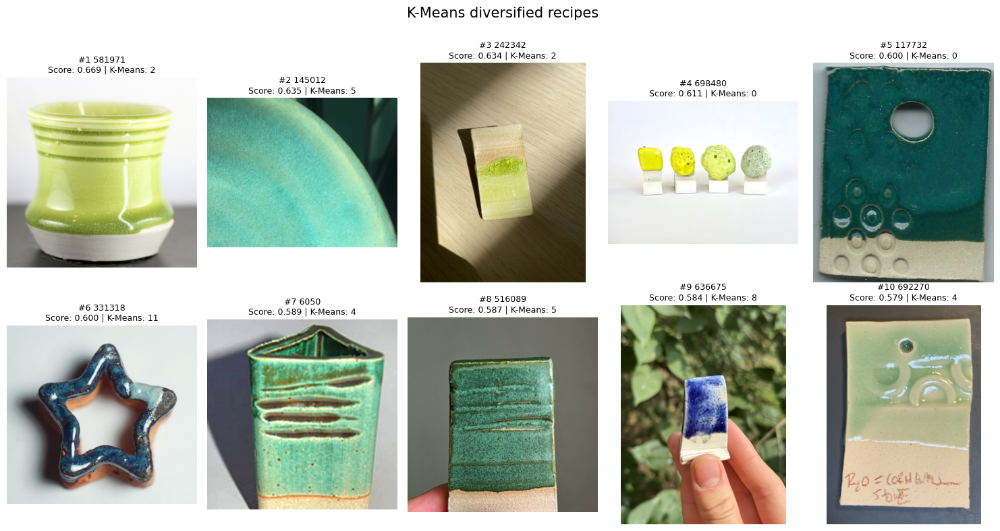

In [17]:
# Change these values to try another text + color query.
query_args = dict(color="Green", surface="Glossy", cone="6", query_hex="#60EB74", top_k=10)
plain = retrieve_glazes(**query_args, diversify=False)
diverse = retrieve_glazes(**query_args, diversify=True, max_per_cluster=2)

show_cols = ["recipe_id", "Name", "color_name", "hex_color", "Surface", "Cone",
             "kmeans_cluster", "latent_similarity", "delta_e_2000",
             "color_score", "final_score", "image_path"]
print("Best matching recipes")
display(plain[[c for c in show_cols if c in plain.columns]])
show_glaze_gallery(plain, "Best matching recipes")

print("Explore different chemical formulations")
display(diverse[[c for c in show_cols if c in diverse.columns]])
show_glaze_gallery(diverse, "K-Means diversified recipes")


Best matching recipes


,recipe_id,color_name,hex_color,Surface,Cone,kmeans_cluster,latent_similarity,delta_e_2000,color_score,final_score,image_path
0,764610,lilac purple,#C994BF,Glossy,5 - 6,11,0.035453,11.722775,0.556472,0.629679,https://cdn.glazy.org/public/uploads/recipes/1...
1,199808,cool white,#CCDADF,Glossy,6,11,0.187602,15.581093,0.458840,0.621056,https://cdn.glazy.org/public/uploads/recipes/0...
2,316608,light gray,#C3C9CA,Glossy,6 - 7,8,0.118446,15.738907,0.455233,0.605783,https://cdn.glazy.org/public/uploads/recipes/0...
3,697765,lilac purple,#BF95BF,Glossy,5.5 - 8,8,-0.031610,12.945417,0.523472,0.603067,https://cdn.glazy.org/public/uploads/recipes/6...
4,356543,pale pink,#D8C8CC,Glossy,6 - 7,2,0.328996,21.627932,0.339122,0.601448,https://cdn.glazy.org/public/uploads/recipes/4...
5,51749,ash gray,#A4B3B6,Glossy,6,11,0.065359,15.741126,0.455183,0.595145,https://cdn.glazy.org/public/uploads/recipes/4...
6,582781,cool gray,#93AAB0,Glossy,5.5 - 11,2,0.185659,19.145611,0.383936,0.590706,https://cdn.glazy.org/public/uploads/recipes/8...
7,696072,light gray,#DAD4DC,Glossy,5 - 7,2,0.290711,22.337517,0.327301,0.589063,https://cdn.glazy.org/public/uploads/recipes/7...
8,581212,dusty pink,#BF919A,Glossy,5 - 7,1,0.209872,20.573680,0.357477,0.584965,https://cdn.glazy.org/public/uploads/recipes/1...
9,698820,pale pink,#DBC8CE,Glossy,6,1,0.209872,20.686098,0.355473,0.584164,https://cdn.glazy.org/public/uploads/recipes/2...


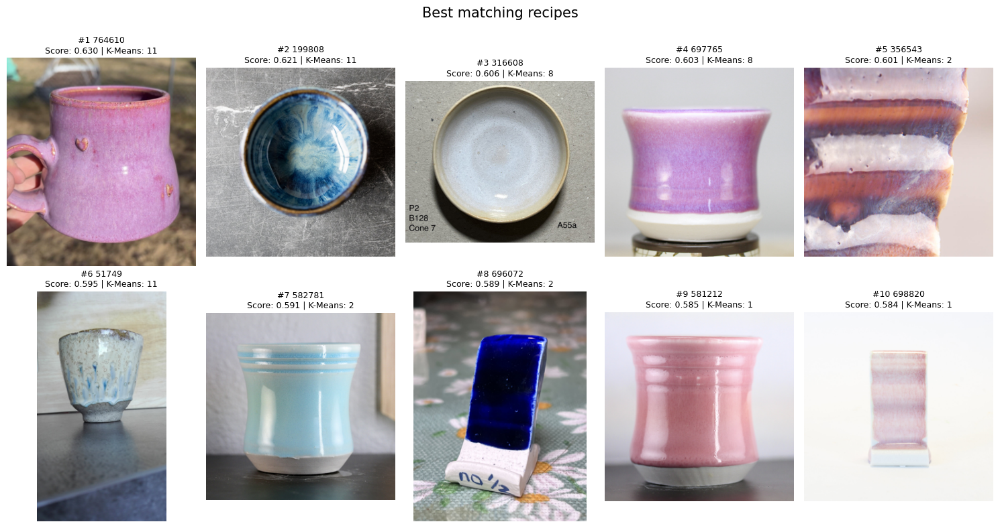

Explore different chemical formulations


,recipe_id,color_name,hex_color,Surface,Cone,kmeans_cluster,latent_similarity,delta_e_2000,color_score,final_score,image_path
0,764610,lilac purple,#C994BF,Glossy,5 - 6,11,0.035453,11.722775,0.556472,0.629679,https://cdn.glazy.org/public/uploads/recipes/1...
1,199808,cool white,#CCDADF,Glossy,6,11,0.187602,15.581093,0.458840,0.621056,https://cdn.glazy.org/public/uploads/recipes/0...
2,316608,light gray,#C3C9CA,Glossy,6 - 7,8,0.118446,15.738907,0.455233,0.605783,https://cdn.glazy.org/public/uploads/recipes/0...
3,697765,lilac purple,#BF95BF,Glossy,5.5 - 8,8,-0.031610,12.945417,0.523472,0.603067,https://cdn.glazy.org/public/uploads/recipes/6...
4,356543,pale pink,#D8C8CC,Glossy,6 - 7,2,0.328996,21.627932,0.339122,0.601448,https://cdn.glazy.org/public/uploads/recipes/4...
5,582781,cool gray,#93AAB0,Glossy,5.5 - 11,2,0.185659,19.145611,0.383936,0.590706,https://cdn.glazy.org/public/uploads/recipes/8...
6,581212,dusty pink,#BF919A,Glossy,5 - 7,1,0.209872,20.573680,0.357477,0.584965,https://cdn.glazy.org/public/uploads/recipes/1...
7,698820,pale pink,#DBC8CE,Glossy,6,1,0.209872,20.686098,0.355473,0.584164,https://cdn.glazy.org/public/uploads/recipes/2...
8,699871,ash gray,#B3B8B9,Glossy,8 - 6,0,-0.023203,16.266117,0.443390,0.572715,https://cdn.glazy.org/public/uploads/recipes/7...
9,155350,light gray,#C7D6D9,Glossy,6 - 7,5,-0.063316,15.429362,0.462334,0.572270,https://cdn.glazy.org/public/uploads/recipes/5...


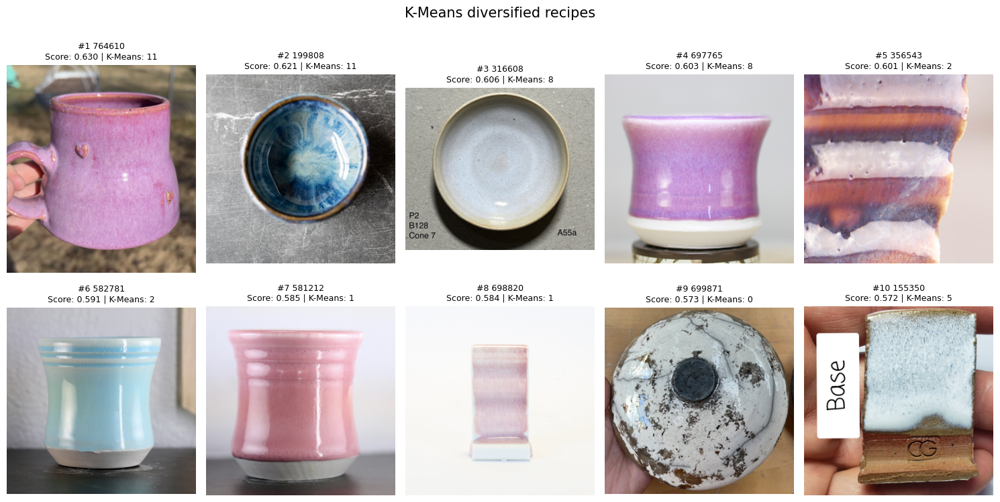

In [18]:
# Change these values to try another text + color query.
query_args = dict(color="Pink", surface="Glossy", cone="6", query_hex="#FFA3F8", top_k=10)
plain = retrieve_glazes(**query_args, diversify=False)
diverse = retrieve_glazes(**query_args, diversify=True, max_per_cluster=2)

show_cols = ["recipe_id", "Name", "color_name", "hex_color", "Surface", "Cone",
             "kmeans_cluster", "latent_similarity", "delta_e_2000",
             "color_score", "final_score", "image_path"]
print("Best matching recipes")
display(plain[[c for c in show_cols if c in plain.columns]])
show_glaze_gallery(plain, "Best matching recipes")

print("Explore different chemical formulations")
display(diverse[[c for c in show_cols if c in diverse.columns]])
show_glaze_gallery(diverse, "K-Means diversified recipes")


Best matching recipes


,recipe_id,color_name,hex_color,Surface,Cone,kmeans_cluster,latent_similarity,delta_e_2000,color_score,final_score,image_path
0,199808,cool white,#CCDADF,Glossy,6,11,0.399118,9.934830,0.608510,0.723228,https://cdn.glazy.org/public/uploads/recipes/0...
1,58641,ash gray,#ABC4C0,Glossy,6,11,0.411527,12.468262,0.536112,0.696750,https://cdn.glazy.org/public/uploads/recipes/4...
2,331318,light gray,#D9DFDD,Glossy,6 - 4,11,0.408852,13.456957,0.510253,0.685872,https://cdn.glazy.org/public/uploads/recipes/1...
3,602915,ash gray,#B6CDCF,Glossy,5.5 - 7,5,0.186587,9.524331,0.621129,0.685769,https://cdn.glazy.org/public/uploads/recipes/1...
4,93944,sky blue,#7CB5C3,Glossy,6,4,0.374553,13.157668,0.517946,0.682089,https://cdn.glazy.org/public/uploads/recipes/4...
5,82611,cool white,#E7F1EB,Glossy,6,11,0.396570,13.811145,0.501297,0.679833,https://cdn.glazy.org/public/uploads/recipes/1...
6,758448,light gray,#D1DADF,Glossy,5 - 6,4,0.260408,11.626305,0.559162,0.675747,https://cdn.glazy.org/public/uploads/recipes/4...
7,479131,sky blue,#75E2EE,Glossy,6 - 6,5,0.119783,9.449238,0.623465,0.673343,https://cdn.glazy.org/public/uploads/recipes/3...
8,588970,powder blue,#95B4C7,Glossy,5.5 - 7,2,0.315522,13.154054,0.518040,0.670320,https://cdn.glazy.org/public/uploads/recipes/7...
9,536722,seafoam green,#ABDBD8,Glossy,5 - 6,4,0.060909,9.033396,0.636564,0.666808,https://cdn.glazy.org/public/uploads/recipes/2...


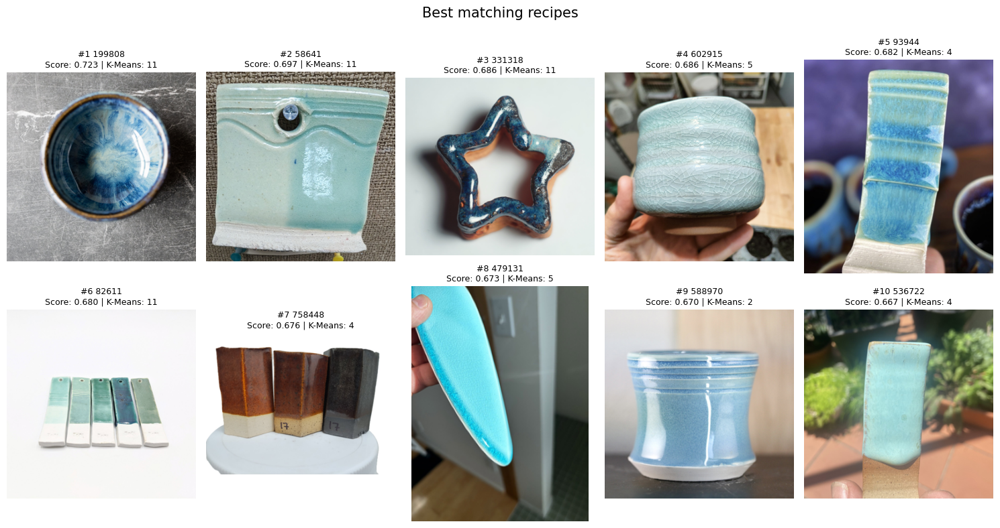

Explore different chemical formulations


,recipe_id,color_name,hex_color,Surface,Cone,kmeans_cluster,latent_similarity,delta_e_2000,color_score,final_score,image_path
0,199808,cool white,#CCDADF,Glossy,6,11,0.399118,9.934830,0.608510,0.723228,https://cdn.glazy.org/public/uploads/recipes/0...
1,58641,ash gray,#ABC4C0,Glossy,6,11,0.411527,12.468262,0.536112,0.696750,https://cdn.glazy.org/public/uploads/recipes/4...
2,602915,ash gray,#B6CDCF,Glossy,5.5 - 7,5,0.186587,9.524331,0.621129,0.685769,https://cdn.glazy.org/public/uploads/recipes/1...
3,93944,sky blue,#7CB5C3,Glossy,6,4,0.374553,13.157668,0.517946,0.682089,https://cdn.glazy.org/public/uploads/recipes/4...
4,758448,light gray,#D1DADF,Glossy,5 - 6,4,0.260408,11.626305,0.559162,0.675747,https://cdn.glazy.org/public/uploads/recipes/4...
5,479131,sky blue,#75E2EE,Glossy,6 - 6,5,0.119783,9.449238,0.623465,0.673343,https://cdn.glazy.org/public/uploads/recipes/3...
6,588970,powder blue,#95B4C7,Glossy,5.5 - 7,2,0.315522,13.154054,0.518040,0.670320,https://cdn.glazy.org/public/uploads/recipes/7...
7,163451,light gray,#CBCFD2,Glossy,5 - 6,0,0.308624,14.075779,0.494707,0.659608,https://cdn.glazy.org/public/uploads/recipes/5...
8,644228,light gray,#D2D6D1,Glossy,5 - 6,0,0.331220,15.178424,0.468171,0.653513,https://cdn.glazy.org/public/uploads/recipes/2...
9,692274,ash gray,#CAD0C1,Glossy,5.5 - 6,2,0.443171,17.976216,0.407053,0.651456,https://cdn.glazy.org/public/uploads/recipes/7...


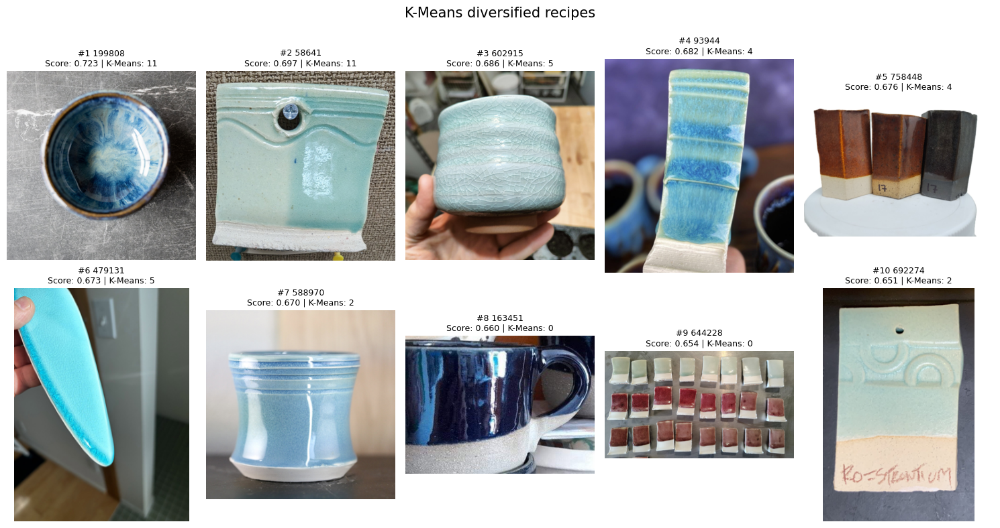

In [19]:
# Change these values to try another text + color query.
query_args = dict(color="Light Blue", surface="Glossy", cone="6", query_hex="#B4E8FA", top_k=10)
plain = retrieve_glazes(**query_args, diversify=False)
diverse = retrieve_glazes(**query_args, diversify=True, max_per_cluster=2)

show_cols = ["recipe_id", "Name", "color_name", "hex_color", "Surface", "Cone",
             "kmeans_cluster", "latent_similarity", "delta_e_2000",
             "color_score", "final_score", "image_path"]
print("Best matching recipes")
display(plain[[c for c in show_cols if c in plain.columns]])
show_glaze_gallery(plain, "Best matching recipes")

print("Explore different chemical formulations")
display(diverse[[c for c in show_cols if c in diverse.columns]])
show_glaze_gallery(diverse, "K-Means diversified recipes")


Best matching recipes


,recipe_id,color_name,hex_color,Surface,Cone,kmeans_cluster,latent_similarity,delta_e_2000,color_score,final_score,image_path
0,367830,chocolate brown,#64312A,Glossy,6,1,0.293702,3.103685,0.856257,0.801243,https://cdn.glazy.org/public/uploads/recipes/3...
1,628959,chocolate brown,#5F3930,Glossy,6,1,0.319419,4.014173,0.818151,0.791144,https://cdn.glazy.org/public/uploads/recipes/5...
2,338414,chocolate brown,#5C302F,Glossy,6,2,0.368028,6.321627,0.729000,0.765206,https://cdn.glazy.org/public/uploads/recipes/1...
3,683916,chocolate brown,#6A3A36,Glossy,5 - 6,5,0.242840,5.026713,0.777761,0.759673,https://cdn.glazy.org/public/uploads/recipes/1...
4,675937,chocolate brown,#663424,Smooth Matte,6,1,0.356922,0.841906,0.958778,0.754896,https://cdn.glazy.org/public/uploads/recipes/3...
5,727209,chestnut brown,#7C362C,Glossy,5 - 6,5,0.242840,5.436831,0.761975,0.753358,https://cdn.glazy.org/public/uploads/recipes/0...
6,256331,chocolate brown,#6E4135,Glossy,6,9,0.141781,4.164537,0.812023,0.753165,https://cdn.glazy.org/public/uploads/recipes/3...
7,764602,coffee brown,#60412B,Glossy,5.5 - 6,9,0.419570,7.999794,0.670327,0.752045,https://cdn.glazy.org/public/uploads/recipes/0...
8,32666,chocolate brown,#673827,Glossy,5 - 6,9,-0.091520,1.799654,0.913947,0.747275,https://cdn.glazy.org/public/uploads/recipes/6...
9,657180,chocolate brown,#71443F,Glossy,6,1,0.297026,6.681584,0.715997,0.745804,https://cdn.glazy.org/public/uploads/recipes/8...


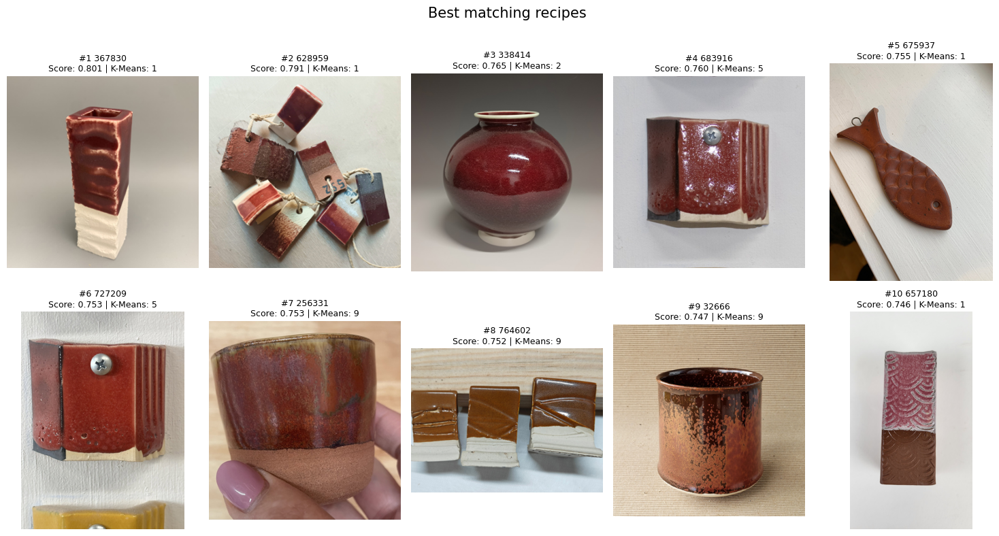

Explore different chemical formulations


,recipe_id,color_name,hex_color,Surface,Cone,kmeans_cluster,latent_similarity,delta_e_2000,color_score,final_score,image_path
0,367830,chocolate brown,#64312A,Glossy,6,1,0.293702,3.103685,0.856257,0.801243,https://cdn.glazy.org/public/uploads/recipes/3...
1,628959,chocolate brown,#5F3930,Glossy,6,1,0.319419,4.014173,0.818151,0.791144,https://cdn.glazy.org/public/uploads/recipes/5...
2,338414,chocolate brown,#5C302F,Glossy,6,2,0.368028,6.321627,0.729000,0.765206,https://cdn.glazy.org/public/uploads/recipes/1...
3,683916,chocolate brown,#6A3A36,Glossy,5 - 6,5,0.242840,5.026713,0.777761,0.759673,https://cdn.glazy.org/public/uploads/recipes/1...
4,727209,chestnut brown,#7C362C,Glossy,5 - 6,5,0.242840,5.436831,0.761975,0.753358,https://cdn.glazy.org/public/uploads/recipes/0...
5,256331,chocolate brown,#6E4135,Glossy,6,9,0.141781,4.164537,0.812023,0.753165,https://cdn.glazy.org/public/uploads/recipes/3...
6,764602,coffee brown,#60412B,Glossy,5.5 - 6,9,0.419570,7.999794,0.670327,0.752045,https://cdn.glazy.org/public/uploads/recipes/0...
7,707568,burgundy red,#7F2227,Glossy,5 - 6,11,0.431358,9.193031,0.631504,0.738873,https://cdn.glazy.org/public/uploads/recipes/6...
8,234971,chocolate brown,#634437,Glossy,6 - 10,11,0.220427,6.922359,0.707429,0.727057,https://cdn.glazy.org/public/uploads/recipes/7...
9,705066,chocolate brown,#674438,Glossy,5 - 7,7,0.083895,5.993464,0.741060,0.713203,https://cdn.glazy.org/public/uploads/recipes/6...


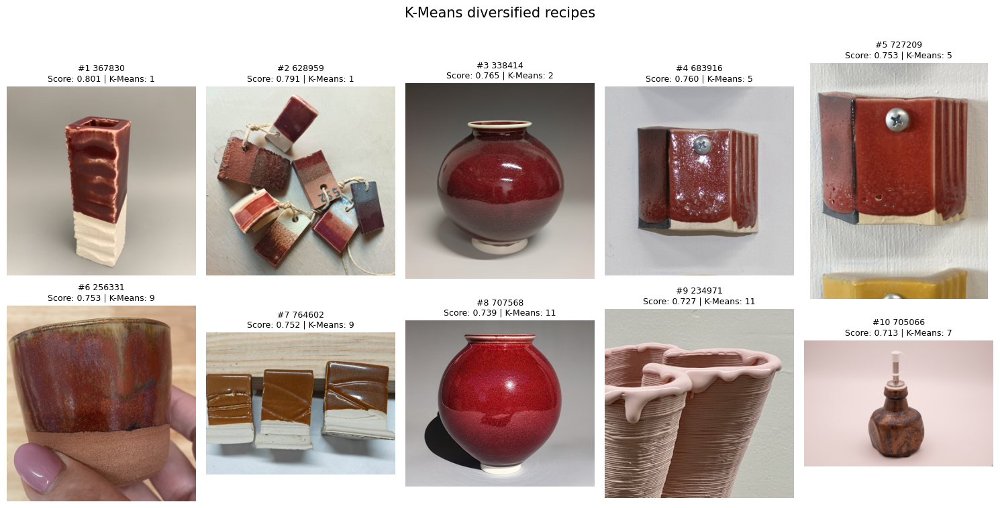

In [20]:
# Change these values to try another text + color query.
query_args = dict(color="Brown", surface="Glossy", cone="6", query_hex="#663426", top_k=10)
plain = retrieve_glazes(**query_args, diversify=False)
diverse = retrieve_glazes(**query_args, diversify=True, max_per_cluster=2)

show_cols = ["recipe_id", "Name", "color_name", "hex_color", "Surface", "Cone",
             "kmeans_cluster", "latent_similarity", "delta_e_2000",
             "color_score", "final_score", "image_path"]
print("Best matching recipes")
display(plain[[c for c in show_cols if c in plain.columns]])
show_glaze_gallery(plain, "Best matching recipes")

print("Explore different chemical formulations")
display(diverse[[c for c in show_cols if c in diverse.columns]])
show_glaze_gallery(diverse, "K-Means diversified recipes")


### Notes

- The retrieval function scores the **full eligible catalog**, not just the top 200 by latent similarity.
- The default weighted score is **40% normalized latent similarity + 40% CIEDE2000 color similarity + 10% surface + 10% cone**. Missing metadata scores zero and is reported in `metadata_coverage`.
- `diversify=False` returns the highest-ranked recipes; `diversify=True` selects from multiple K-Means chemical clusters. K-Means does not add a ranking weight.
- `image_path` is retained for the photo gallery and excluded from model training. Relative paths are resolved from the working directory, or supply `image_base_dir` to the gallery.
- For a held-out evaluation, set `allowed_splits` to the appropriate eligible catalog partition; searching the full catalog is a demonstration, not an unbiased evaluation.
